In [7]:
import numpy as np
import os
from sklearn.cluster import KMeans

In [3]:
prefix = os.path.abspath(os.path.join(os.getcwd(), "./"))
# audio_features = np.squeeze(np.load(os.path.join(prefix, 'Features/whole_samples_clf_256.npz'))['arr_0'], axis=2)

In [78]:
train_features = np.load(os.path.join(prefix, 'DAICCode/Features/train_samples_clf.npz'), allow_pickle=True)['arr_0']
train_targets = np.load(os.path.join(prefix, 'DAICCode/Features/train_labels_clf.npz'), allow_pickle=True)['arr_0']
test_features = np.load(os.path.join(prefix, 'DAICCode/Features/test_samples_clf.npz'), allow_pickle=True)['arr_0']
test_targets = np.load(os.path.join(prefix, 'DAICCode/Features/test_labels_clf.npz'), allow_pickle=True)['arr_0']

train_feat = np.load(os.path.join(prefix, 'DAICCode/Features_E/train_feat.npz'), allow_pickle=True)['arr_0']
test_feat = np.load(os.path.join(prefix, 'DAICCode/Features_E/test_feat.npz'), allow_pickle=True)['arr_0']

In [79]:
X = []
y = []
num = []
for j in range(len(test_features)):
    x = test_feat[j]
    X += x
    num.append(len(x))
    y += [test_targets[j]]*num[-1]
X = np.array(X)
y = np.array(y)

In [80]:
test = []
for j in range(len(test_features)):
    x = test_features[j]
    test += x.tolist()
test = np.array(test)

In [31]:
sum(y)/len(y)

0.28772593526691886

In [33]:
print(sum(num), len(y))

4758 4758


In [36]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(random_state=1234, max_depth=6)
clf.fit(X,y)
y_pred = clf.predict(X)

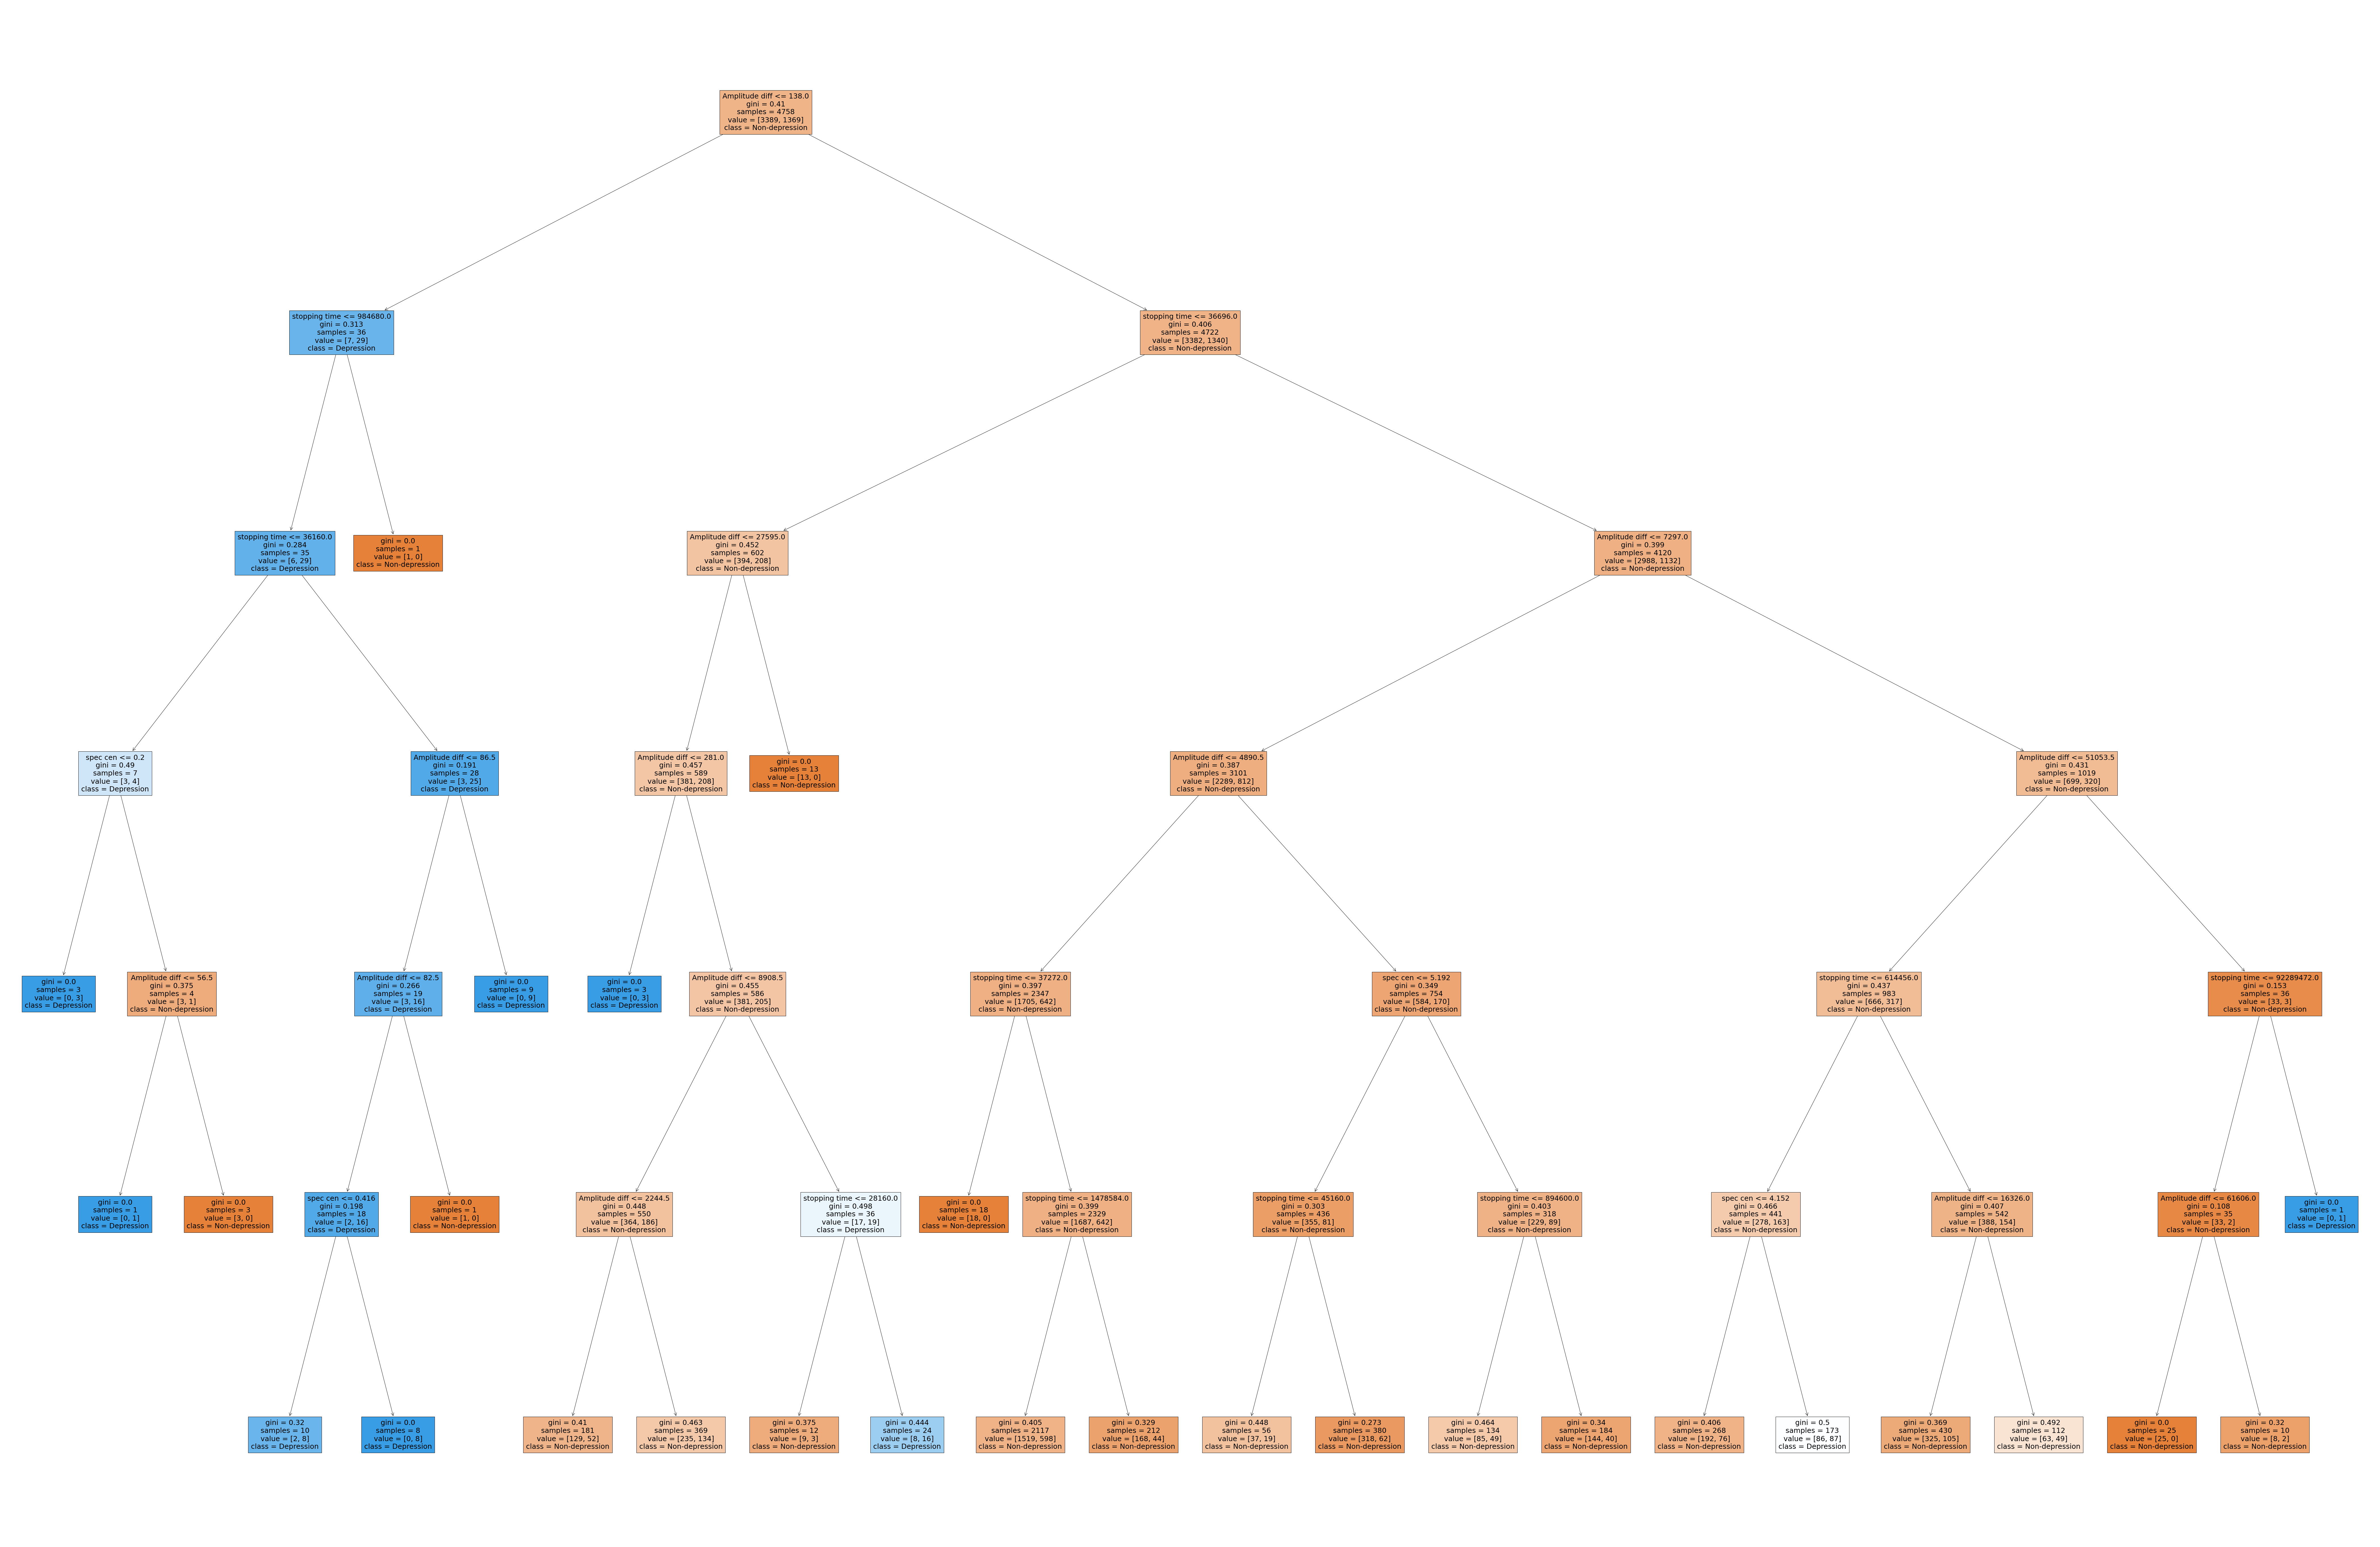

In [37]:
import matplotlib.pyplot as plt
from sklearn import tree
fig = plt.figure(figsize=(150,100))
_ = tree.plot_tree(
    clf,
    feature_names=['Amplitude diff', "spec cen", "stopping time"],
    class_names=["Non-depression","Depression"],
    filled=True
)
fig.savefig("decision_tree.png")

In [38]:
y_new = y[np.where(y_pred-y==0)]

In [39]:
sum(y_new)/len(y_new)

0.039661708953047534

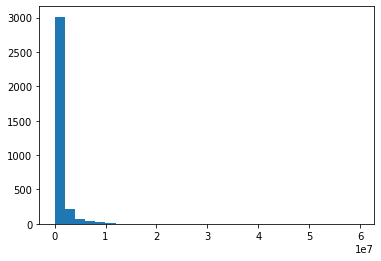

In [61]:
g1 = X[np.where(y==0)][:, 2]
plt.hist(g1[np.where(g1<=10**8)], bins=30)
plt.show()

In [62]:
len(g1[np.where(g1>=0.1*10**7)])

738

In [82]:
len(test[np.where((y==0) & (X[:,2]>=10**6))])

203

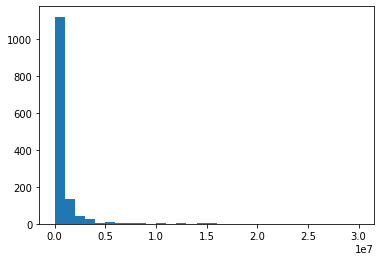

In [63]:
g2 = X[np.where(y==1)][:, 2]
plt.hist(g2[np.where(g2<=10**8)], bins=30)
plt.show()

In [64]:
len(g2[np.where(g2<=0.1*10**7)])

1120

In [71]:
X_feat = []
for j in range(len(train_features)):
    x = train_features[j]
    X_feat += x.tolist()
X_feat = np.array(X_feat)

In [74]:
train_pos = X_feat[np.where((y==1) & (X[:,2]<=10**6))]
train_neg = X_feat[np.where((y==0) & (X[:,2]>=10**6))]
train_y = np.array([1]*len(train_pos)+[0]*len(train_neg))
train_x = np.vstack((train_pos, train_neg))

In [76]:
train_x.shape

(1858, 256)

In [77]:
np.savez(os.path.join(prefix, 'DAICCode/Features_c/train_audio_feat.npz'), train_x)
np.savez(os.path.join(prefix, 'DAICCode/Features_c/train_audio_tar.npz'), train_y)

In [83]:
test_pos = test[np.where((y==1) & (X[:,2]<=10**6))]
test_neg = test[np.where((y==0) & (X[:,2]>=10**6))]
test_y = np.array([1]*len(test_pos)+[0]*len(test_neg))
test_x = np.vstack((test_pos, test_neg))

In [85]:
test_y.shape

(551,)

In [86]:
np.savez(os.path.join(prefix, 'DAICCode/Features_c/test_audio_feat.npz'), test_x)
np.savez(os.path.join(prefix, 'DAICCode/Features_c/test_audio_tar.npz'), test_y)

In [17]:
X

array([[4.353000e+03, 5.600000e-01, 8.109760e+05],
       [4.678000e+03, 1.040000e+00, 9.632000e+04],
       [5.722000e+03, 6.000000e+00, 3.840000e+05],
       ...,
       [3.139000e+03, 3.104000e+00, 1.528960e+05],
       [2.112800e+04, 1.856000e+01, 2.546016e+06],
       [5.121000e+03, 3.216000e+00, 2.829920e+05]])

In [40]:
km = KMeans(n_clusters=2, random_state=1234).fit_predict(X)

In [43]:
sum(km)

1

In [41]:
y

array([0, 0, 0, ..., 0, 0, 0])

In [42]:
sum(y)

1369

In [17]:
diff = km-y

In [18]:
id = np.where(diff == 0)

In [19]:
id

(array([   0,    2,    3, ..., 2596, 2598, 2599]),)

In [23]:
np.sum(train_targets)/len(train_targets)

0.5

In [3]:
test_target = np.load(os.path.join(prefix, 'DAICCode/Features/test_labels_clf.npz'), allow_pickle=True)['arr_0']

In [5]:
test_targets = np.load(os.path.join(prefix, 'DAICCode/Features4/test_labels_clf.npz'), allow_pickle=True)['arr_0']

In [15]:
(np.reshape(test_targets, (33,2)).mean(axis=1)>=1).astype(int)

array([0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0])

In [10]:
train_dep_idxs = np.where(train_targets == 1)[0]
train_non_idxs = np.where(train_targets == 0)[0]

In [11]:
deprep = [train_features[j].shape[0] for j in train_dep_idxs]
nonrep = [train_features[j].shape[0] for j in train_non_idxs]

In [21]:
import matplotlib.pyplot as plt
import scipy.stats as stats

In [33]:
x_lin = np.linspace(20, 80, 601)
kde1, kde2 = stats.gaussian_kde(deprep), stats.gaussian_kde(nonrep)
kde1.set_bandwidth(0.3)
kde2.set_bandwidth(0.3)
y1, y2 = kde1(x_lin), kde2(x_lin)

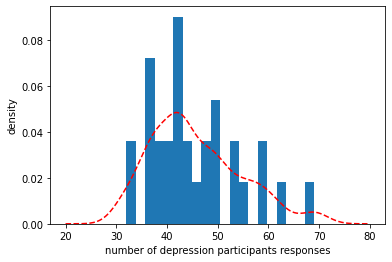

In [32]:
plt.hist(deprep, density=True, bins=20)
plt.plot(x_lin, y1, "r--")
plt.xlabel("number of depression participants responses")
plt.ylabel("density")
plt.show()

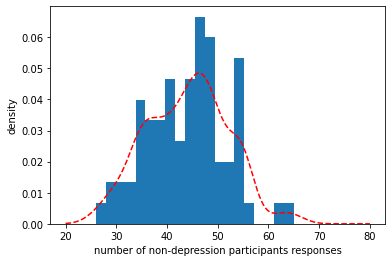

In [34]:
plt.hist(nonrep, density=True, bins=20)
plt.plot(x_lin, y2, "r--")
plt.xlabel("number of non-depression participants responses")
plt.ylabel("density")
plt.show()

In [20]:
print(min(deprep), min(nonrep))
print(max(deprep), max(nonrep))
print(np.mean(deprep), np.mean(nonrep))
print(np.var(deprep), np.var(nonrep))
print(len(deprep), len(nonrep))

32 26
69 65
45.63333333333333 44.01298701298701
79.0988888888889 64.324506662169
30 77


In [57]:
sum([i//5 for i in nonrep])

647

In [50]:
sample = [np.random.choice(8, 2, replace=False) for i in range(2)]
print(sample)

[array([1, 6]), array([3, 0])]


In [64]:
train_features = np.load(os.path.join(prefix, 'DAICCode/Features3/train_samples_clf.npz'), allow_pickle=True)['arr_0']
train_targets = np.load(os.path.join(prefix, 'DAICCode/Features3/train_labels_clf.npz'), allow_pickle=True)['arr_0']

In [65]:
train_features.shape

(520, 5, 256)

In [66]:
train_dep_idxs = np.where(train_targets == 1)[0]
train_non_idxs = np.where(train_targets == 0)[0]

In [67]:
len(train_non_idxs)

260

In [63]:
np.random.choice([1,3,4], 2, replace=False)

array([4, 3])

In [68]:
ttrain_features = np.load(os.path.join(prefix, 'DAICCode/Features3/train_text_clf.npz'), allow_pickle=True)['arr_0']

In [69]:
ttrain_features.shape

(520, 5, 1024)